In [14]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
from itertools import combinations, permutations

1.a

In [18]:
def configuration_model(degrees, seed=None):
    '''
    build a configuration graph from a degree sequence of non-negative integers
    take a node and give it stubs equal to its degree
    then randomly pair up the stubs to form edges
    return error for negative or non-integer degrees, or if the sum of degrees is odd
    make it reproducible with a seed for the random number generator
    '''
    if any(not isinstance(k, (int, np.integer)) or k < 0 for k in degrees):
        raise ValueError("Degrees must be non-negative integers.")
    if sum(degrees) % 2 != 0:
        raise ValueError("The sum of the degree sequence must be even.")
    rng = np.random.default_rng(seed)
    # node i appears k_i times in the stub list
    stubs = np.repeat(np.arange(len(degrees)), degrees)
    rng.shuffle(stubs)
    G = nx.MultiGraph()
    G.add_nodes_from(range(len(degrees)))
    # consecutive pairs of the shuffled stubs are the edges
    G.add_edges_from(stubs.reshape(-1, 2).tolist())
    return G

Let's test it a randomly generated degree sequence, with `seed=10` for reproducibility and visualize. Self-loops count twice toward a node's degree in a `MultiGraph`, so the output degrees should match the input exactly even if the graph has loops or parallel edges.

MultiGraph 8 nodes 22 edges
input:  [7, 9, 3, 2, 8, 8, 5, 2]
output: [7, 9, 3, 2, 8, 8, 5, 2]
degrees match: True
self-loops: [(0, 0), (1, 1), (4, 4), (5, 5), (6, 6)]
multiple edges (>1): {(0, 4): 2, (1, 5): 3, (5, 7): 2}


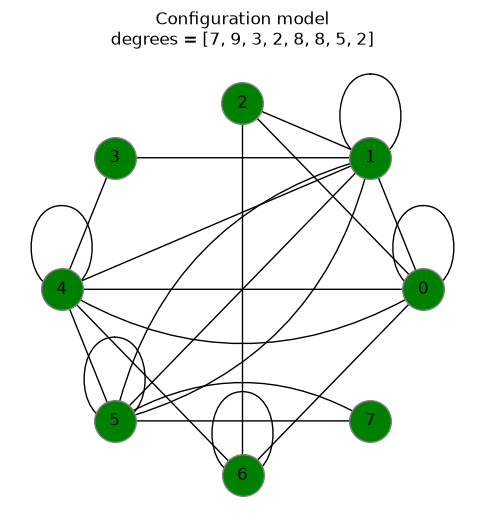

In [19]:
# random degree sequence: 8 degrees between 1 and 9, redrawn until the sum is even
rng = np.random.default_rng(10)
degrees = rng.integers(1, 10, size=8).tolist()
while sum(degrees) % 2 != 0:
    degrees = rng.integers(1, 10, size=8).tolist()

G = configuration_model(degrees, seed=10)
print(type(G).__name__, G.number_of_nodes(), "nodes", G.number_of_edges(), "edges")
print("input: ", degrees)
print("output:", [G.degree(i) for i in range(len(degrees))])
print("degrees match:", [G.degree(i) for i in range(len(degrees))] == degrees)
print("self-loops:", list(nx.selfloop_edges(G)))
print("multiple edges (>1):", {e: m for e, m in Counter(map(tuple, map(sorted, G.edges()))).items() if m > 1})

# circular layout visualization, us n.draw to see all the edges
pos = nx.circular_layout(G)
fig, ax = plt.subplots(figsize=(6, 6))
nx.draw_networkx_nodes(G, pos, node_color="green", edgecolors="grey", node_size=900, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)
# MultiGraph edges are (u, v, key). we should draw each parallel copy with its own curvature
# so duplicates don't sit on top of each other. alternate sides with (-1)^k and scale the curvature with k.
for u, v, k in G.edges(keys=True):
    rad = 0 if k == 0 else 0.3 * (-1) ** k * ((k + 1) // 2)
    nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], arrows=True, arrowstyle="-",
                           connectionstyle=f"arc3,rad={rad}", node_size=900, ax=ax)
ax.set_title(f"Configuration model\ndegrees = {degrees}")
ax.set_axis_off()
plt.show()

Now we can test for bad inputs. An odd sum can't be paired up, and negative or non-integer degrees make no sense, so these should all raise a ValueError.

In [17]:
# odd sum, negative degree, non-integer degree
for bad in ([1, 2], [1, -1], [1.0, 1]):
    try:
        configuration_model(bad)
    except ValueError as e:
        print(bad, "->", e)

[1, 2] -> The sum of the degree sequence must be even.
[1, -1] -> Degrees must be non-negative integers.
[1.0, 1] -> Degrees must be non-negative integers.


1.b

In [21]:
def chung_lu_model(degrees, seed=None):
    '''
    build a chung lu graph from a degree sequence of non-negative integers
    for every pair of nodes i < j, add an edge independently with probability k_i k_j / 2m
    cap the probability at 1, since hubs can push k_i k_j / 2m above 1
    return error for negative or non-integer degrees
    make it reproducible with a seed for the random number generator
    '''
    if any(not isinstance(k, (int, np.integer)) or k < 0 for k in degrees):
        raise ValueError("Degrees must be non-negative integers.")
    rng = np.random.default_rng(seed)
    # 2m is the sum of the degrees
    two_m = sum(degrees)
    G = nx.Graph()
    G.add_nodes_from(range(len(degrees)))
    # each pair is its own coin flip, and i < j so there are no self-loops or duplicate edges
    for i, j in combinations(range(len(degrees)), 2):
        if two_m > 0 and rng.random() < min(1, degrees[i] * degrees[j] / two_m):
            G.add_edge(i, j)
    return G

Let's test it on a randomly generated degree sequence, with `seed=10` for reproducibility and visualize. Each edge is an independent coin flip, so the output degrees will only be approximately the input. The output should be a simple graph, so there are no self-loops or parallel edges.

Graph 8 nodes 14 edges
input:  [7, 9, 3, 2, 8, 8, 5, 2]
output: [5, 4, 2, 2, 4, 5, 5, 1]
self-loops: []


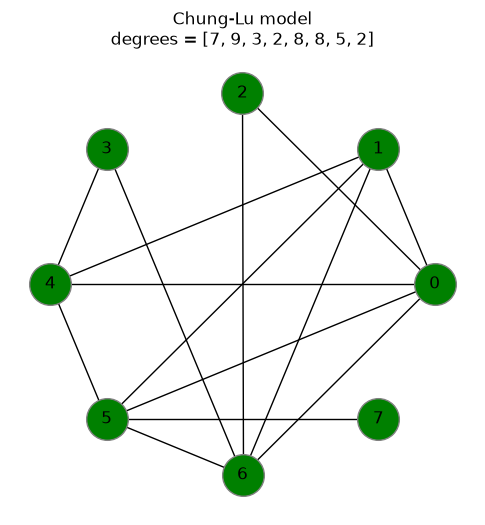

In [24]:
# random degree sequence: 8 degrees between 1 and 9
rng = np.random.default_rng(10)
degrees = rng.integers(1, 10, size=8).tolist()

G = chung_lu_model(degrees, seed=10)
print(type(G).__name__, G.number_of_nodes(), "nodes", G.number_of_edges(), "edges")
print("input: ", degrees)
print("output:", [G.degree(i) for i in range(len(degrees))])
# check for no self-loops
print("self-loops:", list(nx.selfloop_edges(G)))

# circular layout visualization
pos = nx.circular_layout(G)
fig, ax = plt.subplots(figsize=(6, 6))
nx.draw_networkx_nodes(G, pos, node_color="green", edgecolors="grey", node_size=900, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)
# the graph is simple, so every edge can be drawn straight
nx.draw_networkx_edges(G, pos, node_size=900, ax=ax)
ax.set_title(f"Chung-Lu model\ndegrees = {degrees}")
ax.set_axis_off()
plt.show()

Now we can test for bad inputs. Negative or non-integer degrees make no sense, so these should both raise a ValueError. Unlike the configuration model, an odd sum is fine here since nothing has to be paired up.

In [ ]:
# negative degree, non-integer degree
for bad in ([1, -1], [1.0, 1]):
    try:
        chung_lu_model(bad)
    except ValueError as e:
        print(bad, "->", e)